In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa va a ejecutar el proyecto de inversión cuyo cuadro de prelaciones, duraciones (meses), presupuesto por actividad (BAC, k€), duración tope y coste unitario de reducción (k€/mes) se adjunta. El coste de cada actividad se desembolsa uniformemente a lo largo de su duración. Cuando el proyecto termina, la instalación genera un flujo de caja neto de 60 k€ al mes durante 48 meses. La empresa descuenta al 12% anual.

In [4]:
pregunta_1 = "1. Calcule el calendario del proyecto y, a partir del Gantt de inicios más tempranos, el desembolso de cada mes de la fase de inversión.  "
pregunta_2 = "2. Construya el flujo de caja mensual completo (inversión y explotación) y calcule el VAN con la tasa mensual equivalente. ¿Es viable?  "
pregunta_3 = "3. El proyecto sufre un retraso de 3 meses (los desembolsos se producen igual, pero los ingresos empiezan más tarde). ¿Cuánto VAN se pierde? ¿Cuánto vale, por tanto, cada mes de adelanto?  "
pregunta_4 = "4. Aplique Ackoff-Sasieni para reducir la duración del proyecto mes a mes hasta tres meses. Compare el sobrecoste de cada mes con la ganancia de VAN por adelantar los ingresos: ¿cuántos meses conviene acortar?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el calendario del proyecto y, a partir del Gantt de inicios más tempranos, el desembolso de cada mes de la fase de inversión.  

2. Construya el flujo de caja mensual completo (inversión y explotación) y calcule el VAN con la tasa mensual equivalente. ¿Es viable?  

3. El proyecto sufre un retraso de 3 meses (los desembolsos se producen igual, pero los ingresos empiezan más tarde). ¿Cuánto VAN se pierde? ¿Cuánto vale, por tanto, cada mes de adelanto?  

4. Aplique Ackoff-Sasieni para reducir la duración del proyecto mes a mes hasta tres meses. Compare el sobrecoste de cada mes con la ganancia de VAN por adelantar los ingresos: ¿cuántos meses conviene acortar?  

In [5]:
#| tbl-cap: "Datos del proyecto"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, BAC, cap_duration, ucr   
    ('A'     , '---'      , 3       , 175, 2           , 8     ),
    ('B'     , '---'      , 3       , 200, 1           , 9     ),
    ('C'     , '---'      , 2       , 75 , 2           , np.inf),
    ('D'     , 'A,B,C'    , 3       , 125, 3           , np.inf),
    ('E'     , 'C'        , 3       , 125, 2           , 1     ),
    ('F'     , 'D'        , 2       , 100, 1           , 9     ),
    ('G'     , 'E,F'      , 7       , 100, 5           , 8     ),
    ('H'     , 'D,E'      , 6       , 200, 6           , np.inf),
    ('I'     , 'H'        , 2       , 150, 2           , np.inf),
], columns=['activity', 'predecessor', 'duration', 'BAC', 'cap_duration', 'ucr']).set_index('activity')
datos_enunciado

,predecessor,duration,BAC,cap_duration,ucr
activity,,,,,
A,---,3,175,2,8.0
B,---,3,200,1,9.0
C,---,2,75,2,inf
D,"A,B,C",3,125,3,inf
E,C,3,125,2,1.0
F,D,2,100,1,9.0
G,"E,F",7,100,5,8.0
H,"D,E",6,200,6,inf
I,H,2,150,2,inf


El proyecto corresponde al lanzamiento de una aplicación móvil; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de requisitos',
    'B': 'Diseño de la arquitectura',
    'C': 'Diseño de interfaz y prototipo',
    'D': 'Base de datos y modelo',
    'E': 'API del servidor',
    'F': 'Pantallas principales',
    'G': 'Módulo de pagos',
    'H': 'Notificaciones y sincronización',
    'I': 'Pruebas de integración',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de requisitos
B,Diseño de la arquitectura
C,Diseño de interfaz y prototipo
D,Base de datos y modelo
E,API del servidor
F,Pantallas principales
G,Módulo de pagos
H,Notificaciones y sincronización
I,Pruebas de integración


# Resolución

In [7]:
def van(flujos, k):
    '''Valor actual neto de una lista de flujos (el primero en t = 0) a la tasa k.'''
    return float(sum(f / (1 + k) ** t for t, f in enumerate(flujos)))

def tir(flujos):
    '''Tasa que anula el VAN (por bisección entre −99 % y 1000 %).'''
    from scipy.optimize import brentq
    return float(brentq(lambda k: van(flujos, k), -0.99, 10.0))

def tabla_descuento(flujos, k):
    '''Año, flujo, factor de descuento, valor actual y valores acumulados (simple y descontado).'''
    t = pd.DataFrame({'flujo': list(flujos)}, index=pd.Index(range(len(flujos)), name='año'))
    t['(1 + k)^-t'] = [(1 + k) ** -i for i in t.index]
    t['valor actual'] = t['flujo'] * t['(1 + k)^-t']
    t['acumulado'] = t['flujo'].cumsum()
    t['acumulado descontado'] = t['valor actual'].cumsum()
    return t

def payback(flujos, k=None):
    '''Periodo de recuperación (años, con interpolación lineal dentro del año); descontado si se da k.'''
    acum = 0.0
    for t, f in enumerate(flujos):
        v = f if k is None else f / (1 + k) ** t
        if t > 0 and acum < 0 <= acum + v:
            return float(t - 1 + (-acum) / v)
        acum += v
    return float('inf')

def anualidad_equivalente(VAN, k, n):
    '''Anualidad constante durante n años cuyo valor actual es VAN.'''
    return float(VAN * k / (1 - (1 + k) ** -n))

In [8]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
F, N, k, retraso = 60.0, 48, 0.12, 3
k_mensual = (1 + k) ** (1 / 12) - 1
I0 = float(datos_proyecto['BAC'].sum())

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. Calcule el calendario del proyecto y, a partir del Gantt de inicios más tempranos, el desembolso de cada mes de la fase de inversión.  

In [10]:
#| tbl-cap: "Calendario del proyecto (meses)"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
proyecto.display_calendario(datos_proyecto['duration'])

,inicio_mas_temprano,fin_mas_temprano,H_total
activity,,,
A,0,3,0
B,0,3,0
C,0,2,1
D,3,6,0
E,2,5,2
F,6,8,0
G,8,15,0
H,6,12,1
I,12,14,1


Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

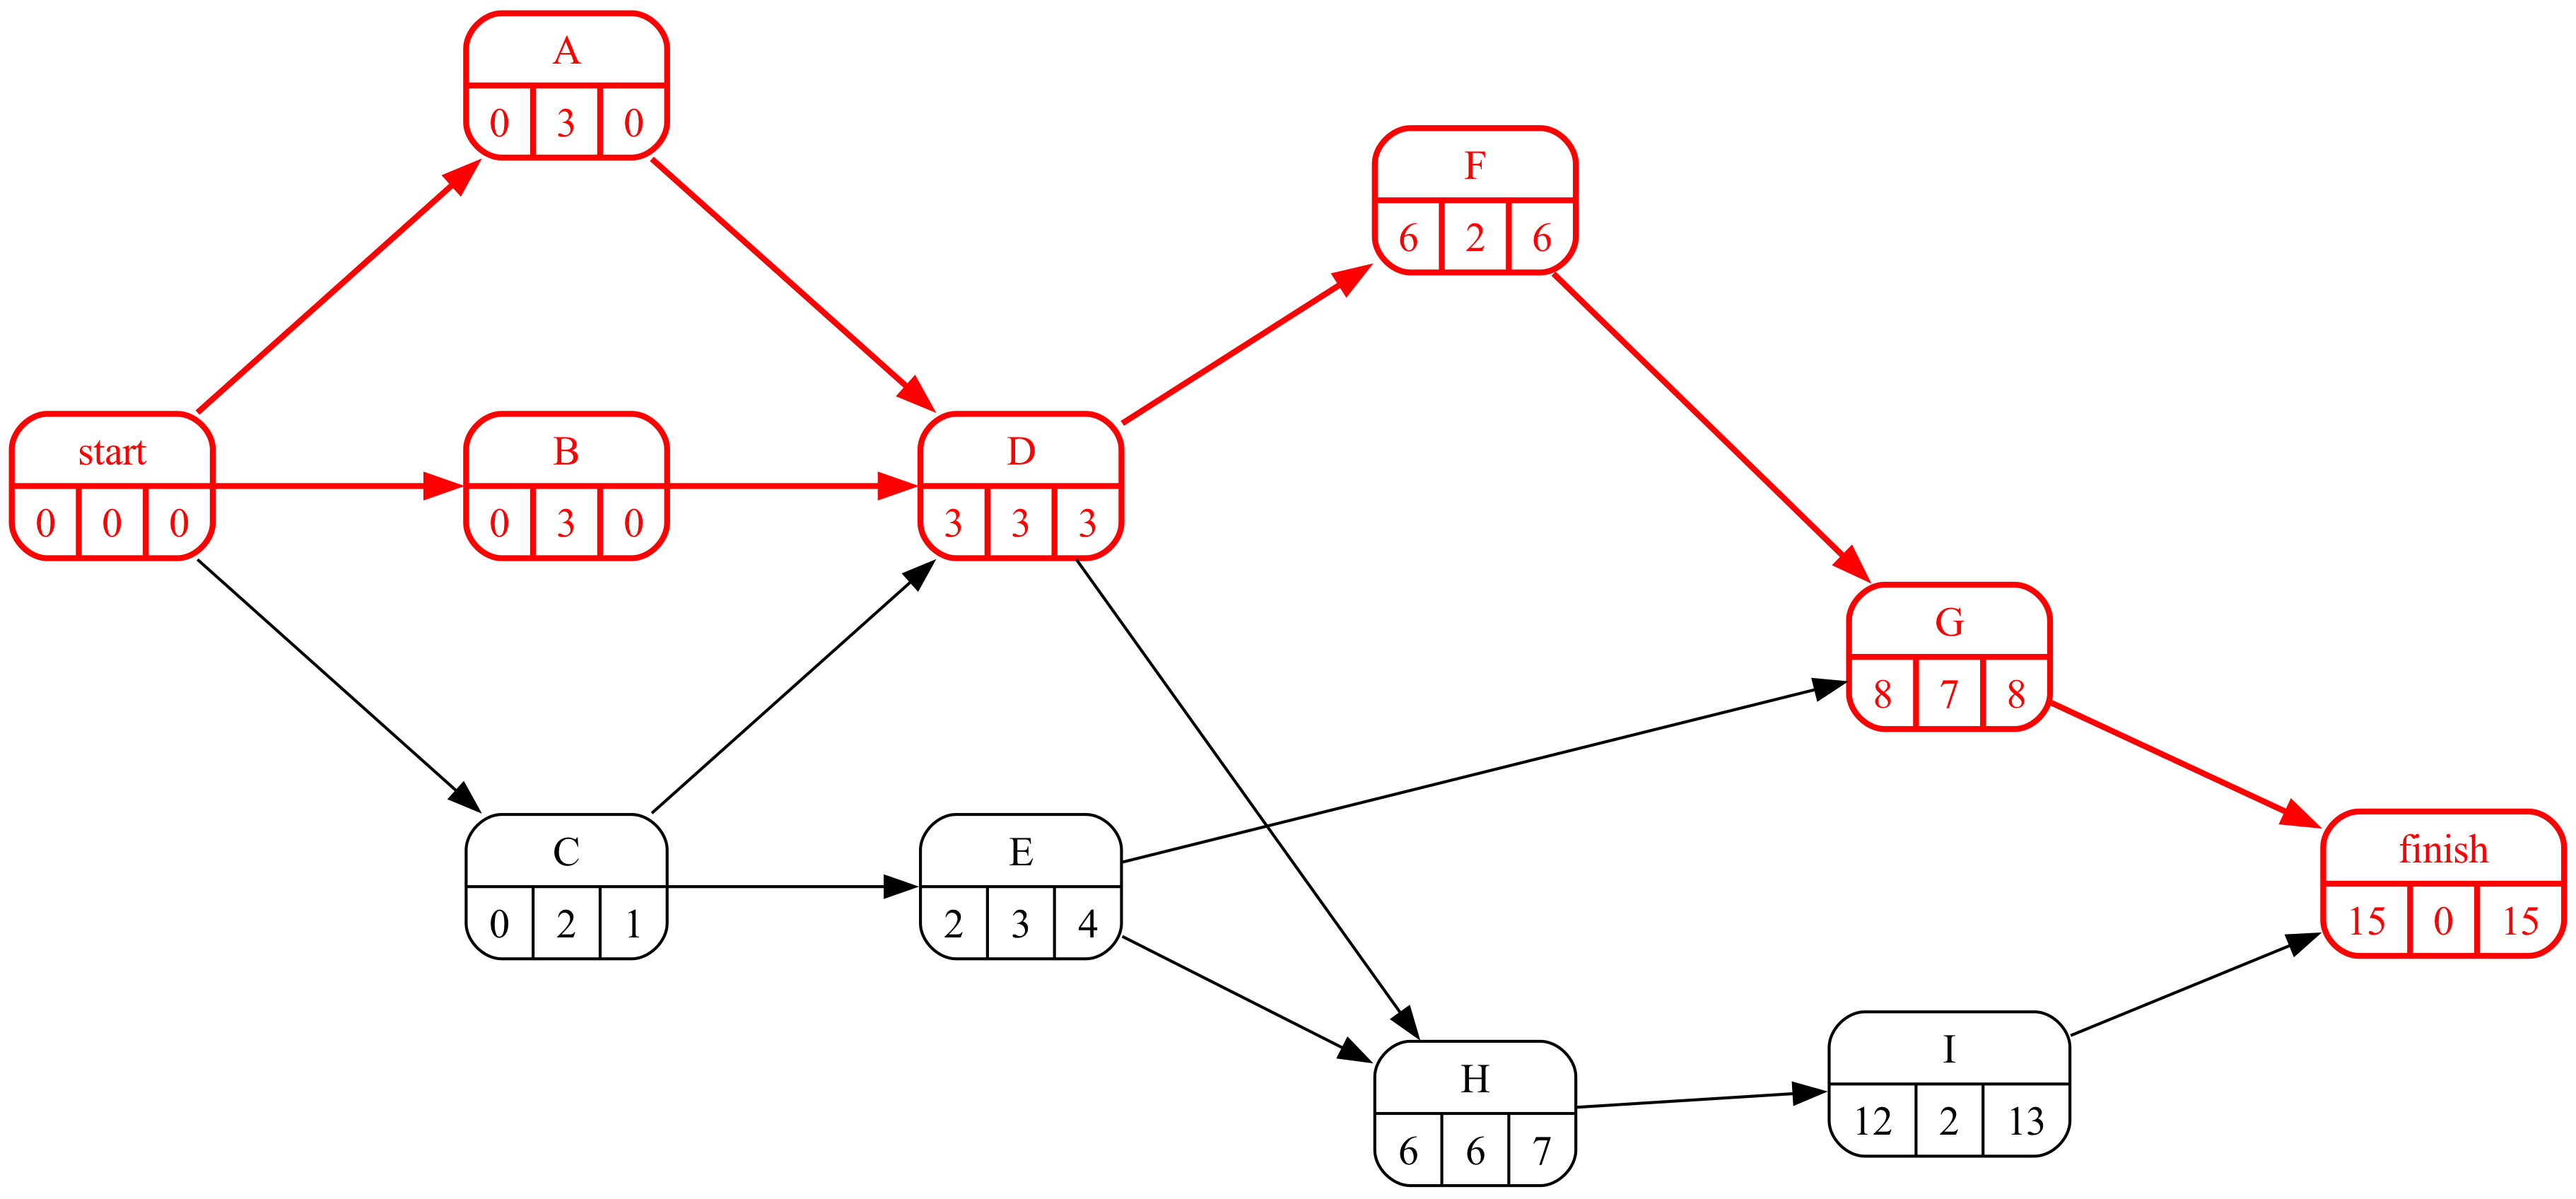

In [11]:
#| fig-cap: "Grafo Roy con el camino crítico"
#| label: fig-grafo
proyecto.display_roy_pasos(datos_proyecto['duration'])

El coste mensual de cada actividad es su BAC dividido por su duración. Escribiéndolo en cada casilla del Gantt de inicios más tempranos, el desembolso de cada mes es la suma de su columna (fila *Total*) y la fila *Acumulado* muestra lo invertido hasta ese mes; la columna *Total* de cada actividad recupera su BAC.

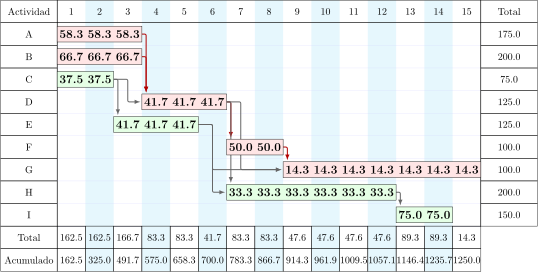

In [12]:
#| fig-cap: "Gantt con el coste mensual de cada actividad (k€): la fila Total es el desembolso del mes"
#| label: fig-ganttCostes
datos_gantt = datos_proyecto.copy()
datos_gantt['coste_mensual'] = datos_gantt['BAC'] / datos_gantt['duration']
gantt_costes, dibujo = proyecto.gantt(datos_gantt, 'duration', 'coste_mensual', total='ambas', acumulado=True, tikz=True,
                                      params=dict(inner_text_digits=1, **GANTT_PARAMS))
pinta_tikz(dibujo)

In [13]:
def desembolsos(cal, dur, duraciones=None):
    '''Desembolso de cada mes (1..T) repartiendo el BAC de cada actividad uniformemente.'''
    duraciones = datos_proyecto['duration'] if duraciones is None else duraciones
    pagos = pd.Series(0.0, index=range(1, int(dur) + 1))
    for a, fila in datos_proyecto.iterrows():
        es, d = int(cal.loc[a, 'inicio_mas_temprano']), int(duraciones[a])
        for m in range(es + 1, es + d + 1):
            pagos[m] += fila['BAC'] / d
    return pagos
pagos = desembolsos(calendario, duracion)
fila_total = gantt_costes.data.loc['Total'].drop('Total', errors='ignore').astype(float)
display(pd.DataFrame({'desembolso (k€)': pagos, 'fila Total del Gantt': fila_total.values[:len(pagos)]}).round(1).T)
Markdown(f'La fase de inversión dura {duracion} meses y suma {pagos.sum():.0f} k€ (= Σ BAC = {I0:.0f}).')

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
desembolso (k€),162.5,162.5,166.7,83.3,83.3,41.7,83.3,83.3,47.6,47.6,47.6,47.6,89.3,89.3,14.3
fila Total del Gantt,162.5,162.5,166.7,83.3,83.3,41.7,83.3,83.3,47.6,47.6,47.6,47.6,89.3,89.3,14.3


La fase de inversión dura 15 meses y suma 1250 k€ (= Σ BAC = 1250).

## Apartado 2

In [14]:
display(Markdown(pregunta_2))

2. Construya el flujo de caja mensual completo (inversión y explotación) y calcule el VAN con la tasa mensual equivalente. ¿Es viable?  

Cada mes es un periodo: en los meses 1…T el flujo es −desembolso; en los T+1…T+N, +F. La tasa mensual equivalente cumple $(1 + k_m)^{12} = 1 + k$.

In [15]:
def flujo_mensual(pagos, inicio_ingresos, sobrecoste=0.0):
    T = len(pagos)
    f = [0.0] + [-float(x) for x in pagos] + [0.0] * (inicio_ingresos - T) + [F] * N
    f[1] -= sobrecoste
    return f
flujos = flujo_mensual(pagos, duracion)
VAN = van(flujos, k_mensual)
resumen = pd.DataFrame({'mes': range(len(flujos)), 'flujo (k€)': flujos}).set_index('mes')
display(resumen.T.iloc[:, :duracion + 4].round(1))
Markdown(f'k mensual = (1 + {k})^(1/12) − 1 = {k_mensual:.4%}. VAN = {VAN:.1f} k€ (valor actual de los ingresos {van([0] * (duracion + 1) + [F] * N, k_mensual):.1f} '
         f'menos valor actual de los desembolsos {-van([0] + [-x for x in pagos], k_mensual):.1f}): {"viable" if VAN > 0 else "no viable"}.')

mes,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
flujo (k€),0.0,-162.5,-162.5,-166.7,-83.3,-83.3,-41.7,-83.3,-83.3,-47.6,-47.6,-47.6,-47.6,-89.3,-89.3,-14.3,60.0,60.0,60.0


k mensual = (1 + 0.12)^(1/12) − 1 = 0.9489%. VAN = 821.4 k€ (valor actual de los ingresos 2000.3 menos valor actual de los desembolsos 1178.9): viable.

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. El proyecto sufre un retraso de 3 meses (los desembolsos se producen igual, pero los ingresos empiezan más tarde). ¿Cuánto VAN se pierde? ¿Cuánto vale, por tanto, cada mes de adelanto?  

In [17]:
VAN_retraso = van(flujo_mensual(pagos, duracion + retraso), k_mensual)
perdida = VAN - VAN_retraso
valor_mes = [VAN - van(flujo_mensual(pagos, duracion + m), k_mensual) for m in range(1, retraso + 1)]
display(pd.DataFrame({'meses de retraso': range(1, retraso + 1), 'VAN perdido (k€)': valor_mes}).set_index('meses de retraso').T.round(1))
Markdown(f'''Con {retraso} meses de retraso el VAN baja de {VAN:.1f} a {VAN_retraso:.1f} k€: se pierden {perdida:.1f} k€, unos {perdida / retraso:.1f} k€ por mes. Cada mes de adelanto vale aproximadamente lo mismo (algo más los primeros, porque los ingresos que se desplazan son los más cercanos): es el precio máximo que merece la pena pagar por acortar el proyecto un mes.''')

meses de retraso,1,2,3
VAN perdido (k€),18.8,37.4,55.9


Con 3 meses de retraso el VAN baja de 821.4 a 765.5 k€: se pierden 55.9 k€, unos 18.6 k€ por mes. Cada mes de adelanto vale aproximadamente lo mismo (algo más los primeros, porque los ingresos que se desplazan son los más cercanos): es el precio máximo que merece la pena pagar por acortar el proyecto un mes.

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. Aplique Ackoff-Sasieni para reducir la duración del proyecto mes a mes hasta tres meses. Compare el sobrecoste de cada mes con la ganancia de VAN por adelantar los ingresos: ¿cuántos meses conviene acortar?  

In [19]:
#| tbl-cap: "Algoritmo de Ackoff-Sasieni (hasta tres meses)"
#| label: tbl-ackoff
tabla_ackoff, pasos, duraciones_reducidas, margen = proyecto.ackoff(
    durations=datos_proyecto['duration'], min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'], reduction=3, report=False)
proyecto.display_ackoff_pasos_tikz(
    durations=datos_proyecto['duration'],
    min_durations=datos_proyecto['cap_duration'],
    costs=datos_proyecto['ucr'],
    reduction=3)

,A,B,C,D,E,F,G,H,I,0,1,2
Route_1,8.0,,,inf,,9.0,8.0,,,15.0,14.0,13.0
Route_2,8.0,,,inf,,,8.0,,,13.0,12.0,11.0
Route_3,8.0,,,inf,,,,inf,inf,14.0,14.0,13.0
Route_4,,9.0,,inf,,9.0,8.0,,,15.0,14.0,13.0
Route_5,,9.0,,inf,,,8.0,,,13.0,12.0,11.0
Route_6,,9.0,,inf,,,,inf,inf,14.0,14.0,13.0
Route_7,,,inf,inf,,9.0,8.0,,,14.0,13.0,13.0
Route_8,,,inf,inf,,,8.0,,,12.0,11.0,11.0
Route_9,,,inf,inf,,,,inf,inf,13.0,13.0,13.0
Route_10,,,inf,,1.0,,8.0,,,12.0,11.0,11.0


In [20]:
filas = []
acumulado = 0.0
d = datos_proyecto['duration'].copy()
for paso, acts in sorted(pasos.items()):
    coste = float(sum(datos_proyecto.loc[a, 'ucr'] for a in acts)); acumulado += coste
    for a in acts: d[a] -= 1
    p2 = proyecto.copy(); cal2 = p2.calendar(d); dur2 = int(p2.duration(d))
    VAN2 = van(flujo_mensual(desembolsos(cal2, dur2, d), dur2, sobrecoste=acumulado), k_mensual)
    filas.append({'meses acortados': paso + 1, 'actividades': ', '.join(acts), 'sobrecoste del mes (k€)': coste,
                  'sobrecoste acumulado': acumulado, 'duración': dur2, 'VAN (k€)': VAN2, 'ganancia de VAN frente a no acortar': VAN2 - VAN})
decision = pd.DataFrame(filas).set_index('meses acortados')
display(decision.round(1))
mejor = decision['VAN (k€)'].idxmax() if decision['VAN (k€)'].max() > VAN else 0
Markdown(f'''Conviene acortar {mejor} mes(es): el VAN máximo es {max(VAN, decision["VAN (k€)"].max()):.1f} k€. Cada mes de reducción compensa mientras su sobrecoste (pagado al principio) sea menor que el VAN que gana adelantar un mes los ingresos; como el sobrecoste de Ackoff-Sasieni crece paso a paso y el valor de un mes de adelanto es casi constante, hay un punto de corte.''')

,actividades,sobrecoste del mes (k€),sobrecoste acumulado,duración,VAN (k€),ganancia de VAN frente a no acortar
meses acortados,,,,,,
1,G,8.0,8.0,14,832.0,10.6
2,"A, B",17.0,25.0,13,826.7,5.4


Conviene acortar 1 mes(es): el VAN máximo es 832.0 k€. Cada mes de reducción compensa mientras su sobrecoste (pagado al principio) sea menor que el VAN que gana adelantar un mes los ingresos; como el sobrecoste de Ackoff-Sasieni crece paso a paso y el valor de un mes de adelanto es casi constante, hay un punto de corte.